# Lorenz方程式

SciPyのODEソルバーでカオス的な流れを計算し、3次元軌道を描きます。初期値、係数、終了時刻を変えて挙動を比べます。

Lorenz方程式は
$$
\begin{aligned}
\dot{x}&=\sigma(y-x),\\
\dot{y}&=x(\rho-z)-y,\\
\dot{z}&=xy-\beta z
\end{aligned}
$$
です。標準的な例として $\sigma=10,\ \beta=8/3,\ \rho=28$ を使います。長時間後の軌道は初期値に敏感なので、有限の数値解を長期予測と解釈しないでください。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def lorenz(t, state, sigma, beta, rho):
    x, y, z = state
    return [sigma * (y - x),
            x * (rho - z) - y,
            x * y - beta * z]


In [2]:
sigma = 10.0
beta = 8.0 / 3.0
rho = 28.0
initial_state = np.array([1.0, 1.0, 1.0])
t_start, t_end = 0.0, 40.0
time_points = np.linspace(t_start, t_end, 4001)

solution = solve_ivp(
    lorenz, (t_start, t_end), initial_state,
    args=(sigma, beta, rho), t_eval=time_points,
    rtol=1e-9, atol=1e-11, max_step=0.02
)
assert solution.success
assert solution.y.shape == (3, len(time_points))
assert np.isfinite(solution.y).all()
print(f"success={solution.success}, output points={len(solution.t)}")


success=True, output points=4001


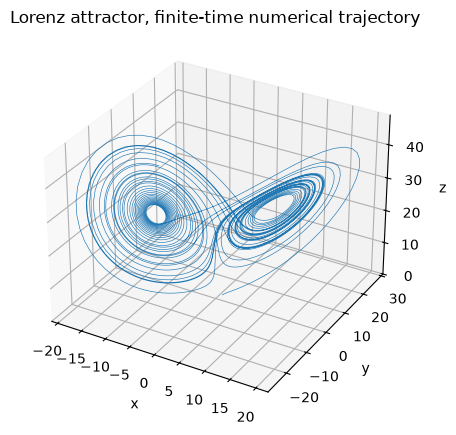

In [3]:
x, y, z = solution.y
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot(x, y, z, lw=0.45)
ax.set(xlabel="x", ylabel="y", zlabel="z",
       title="Lorenz attractor, finite-time numerical trajectory")
plt.show()


## 初期値への敏感さ

同じ係数と、わずかに異なる初期値を使います。短時間は似た軌道でも、時間とともに差が広がります。数値解は許容誤差内で近似されますが、カオス系ではその精度を有限時間より先へ延長できません。

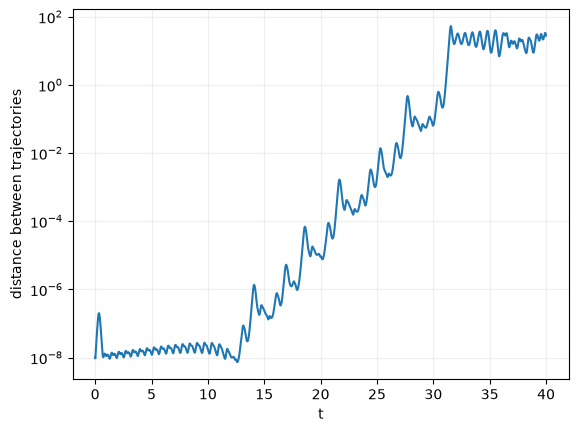

In [4]:
perturbed = solve_ivp(
    lorenz, (t_start, t_end), initial_state + [1e-8, 0.0, 0.0],
    args=(sigma, beta, rho), t_eval=time_points,
    rtol=1e-9, atol=1e-11, max_step=0.02
)
assert perturbed.success
difference = np.linalg.norm(solution.y - perturbed.y, axis=0)
plt.semilogy(time_points, np.maximum(difference, 1e-16))
plt.xlabel("t")
plt.ylabel("distance between trajectories")
plt.grid(alpha=0.2)
plt.show()


### 演習

- 初期条件を少しずつ変え、軌道間距離が広がる時間を比べる。
- rhoを変えて軌道の形を調べる。
- t_endやmax_stepを変え、描画の分解能と積分コストを確認する。